In [6]:
import os, glob
import numpy as np
import tensorflow as tf
import pandas as pd

## Prepare dataset

In [7]:
CAPTURES = "../dataset/captures"
MAX_LEN  = 100 
N_CH     = 6 
# Binary problem: one sigmoid output. 0 = extension, 1 = flexion.
classes = ["label_WRIST_EXTENSION", "label_WRIST_FLEXION"]
class_to_id = {c: i for i, c in enumerate(classes)}

for cls in classes:
    assert glob.glob(os.path.join(CAPTURES, cls, "*.csv")), f"no csv for {cls}"

lengths = []
"""
Load and preprocess the gesture recordings to create the dataset for training the MLP.

For each gesture class, the function:
1. Loads the accelerometer and gyroscope measurements from CSV files.
2. Creates a fixed-size sequence using zero-padding or truncation.
3. Flattens the 2D sensor matrix into a 1D feature vector.
4. Assigns a numerical label to identify the gesture.

Finally, X contains the input features and y contains the corresponding gesture labels.
"""

X, y = [], []
for cls in classes:
    for path in glob.glob(os.path.join(CAPTURES, cls, "*.csv")):
        rows = np.loadtxt(path, delimiter=",", skiprows=1, usecols=range(4, 10))
        seq = np.zeros((MAX_LEN, N_CH), dtype=np.float32)   
        n = min(rows.shape[0], MAX_LEN)
        seq[:n] = rows[:n]
        X.append(seq.flatten())          
        y.append(class_to_id[cls])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)   # 0.0 / 1.0
print("X", X.shape, "classes", classes)  

X (60, 600) classes ['label_WRIST_EXTENSION', 'label_WRIST_FLEXION']


## Analyze dataset

In [8]:
CHANNELS = ["ax", "ay", "az", "gx", "gy", "gz"]


def class_balance(y, classes):
    """Print the number and share of samples per gesture class."""
    labels, counts = np.unique(y, return_counts=True)
    for lab, cnt in zip(labels, counts):
        print(f"  {classes[int(lab)]:24s} {int(cnt):3d}  ({cnt / len(y):.0%})")
    print(f"  total {len(y)} samples")


def sensor_stats(X, channels=CHANNELS):
    """Per-channel min/max/mean/std over the (samples, MAX_LEN, N_CH) tensor."""
    X3 = X.reshape(len(X), MAX_LEN, N_CH)
    for c, name in enumerate(channels):
        ch = X3[:, :, c]
        print(f"  {name:3s} min={ch.min():8.2f} max={ch.max():8.2f} "
              f"mean={ch.mean():8.2f} std={ch.std():8.2f}")
    print(f"  any NaN: {np.isnan(X).any()}  any Inf: {np.isinf(X).any()}")


print(f"X {X.shape}  y {y.shape}")
print("class balance:")
class_balance(y, classes)
print("\nper-channel stats (all samples):")
sensor_stats(X)

X (60, 600)  y (60,)
class balance:
  label_WRIST_EXTENSION     30  (50%)
  label_WRIST_FLEXION       30  (50%)
  total 60 samples

per-channel stats (all samples):
  ax  min=   -1.18 max=    1.02 mean=   -0.00 std=    0.81
  ay  min=   -0.21 max=    0.48 mean=    0.18 std=    0.08
  az  min=   -1.29 max=    0.67 mean=   -0.41 std=    0.43
  gx  min=  -76.06 max=  118.25 mean=   -3.07 std=   13.26
  gy  min= -221.25 max=  197.38 mean=    5.95 std=   51.84
  gz  min=  -50.47 max=   58.85 mean=   -6.97 std=    8.29
  any NaN: False  any Inf: False


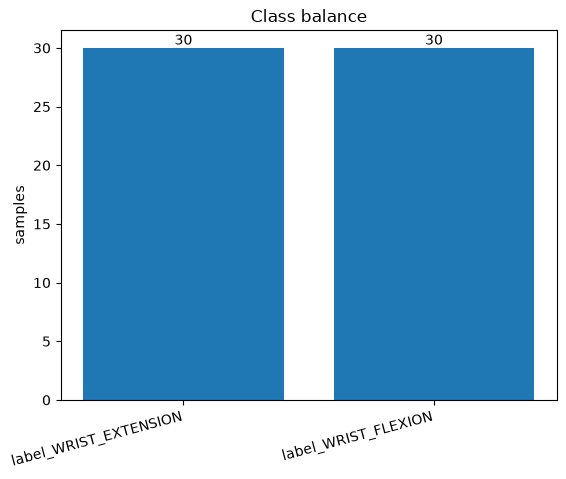

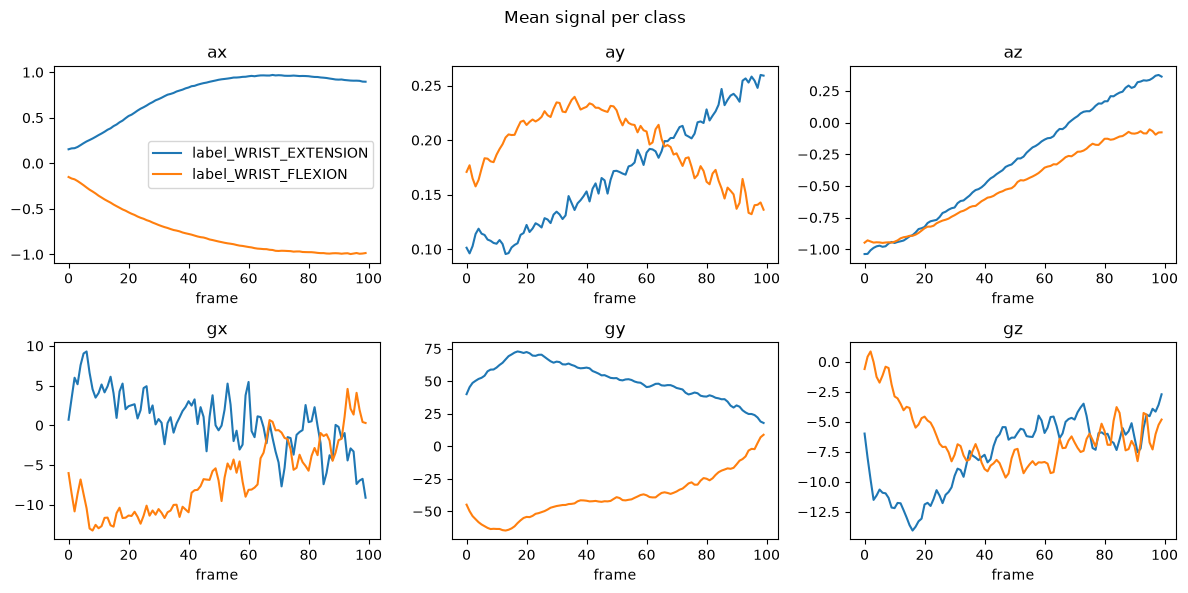

In [10]:
import matplotlib.pyplot as plt

X3 = X.reshape(len(X), MAX_LEN, N_CH)


def plot_class_balance(y, classes):
    labels, counts = np.unique(y, return_counts=True)
    bars = plt.bar([classes[int(l)] for l in labels], counts)
    plt.ylabel("samples")
    plt.title("Class balance")
    plt.xticks(rotation=15, ha="right")
    for b, c in zip(bars, counts):
        plt.text(b.get_x() + b.get_width() / 2, c, str(c), ha="center", va="bottom")

def plot_mean_signal(X3, y, classes, channels=CHANNELS):
    fig, axes = plt.subplots(2, 3, figsize=(12, 6))
    for c, (name, ax) in enumerate(zip(channels, axes.flat)):
        for k in np.unique(y):
            ax.plot(X3[y == k][:, :, c].mean(axis=0), label=classes[int(k)])
        ax.set_title(name)
        ax.set_xlabel("frame")
    axes[0, 0].legend()
    fig.suptitle("Mean signal per class")
    fig.tight_layout()


plot_class_balance(y, classes)
plot_mean_signal(X3, y, classes)

## Hyperparameter tuning 

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import keras_tuner as kt
import numpy as np
import tensorflow as tf

# 1. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

# 2. Normalize data
scaler = StandardScaler().fit(X_train)

X_train = scaler.transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)


# 3. Build neural network
def build_model(hp):
    model = tf.keras.Sequential()

    model.add(tf.keras.layers.Input(shape=(600,)))

    for i in range(hp.Int("num_layers", 1, 3)):
        model.add(tf.keras.layers.Dense(
            units=hp.Int(
                f"units_{i}",
                min_value=16,
                max_value=128,
                step=16
            ),
            activation="relu"
        ))

    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Choice("lr", [1e-2, 1e-3, 1e-4])
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# 4. Configure Keras Tuner
tuner = kt.RandomSearch(
    build_model,
    objective="val_accuracy",
    max_trials=10,
    directory="results",
    project_name="gesture_recognition"
)

# 5. Search for the best architecture
tuner.search(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30
)

# 6. Retrieve best model
best_model = tuner.get_best_models(num_models=1)[0]

# 7. Retrieve best hyperparameters
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best hyperparameters:", best_hp.values)

# 8. Evaluate using test dataset
test_loss, test_accuracy = best_model.evaluate(X_test, y_test)

print("Test accuracy:", test_accuracy)



Reloading Tuner from results/gesture_recognition/tuner0.json


/home/jordi/MERIT/IOTSS/omniflux/Train/enviro/lib/python3.14/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


Best hyperparameters: {'num_layers': 1, 'units_0': 32, 'lr': 0.01, 'units_1': 64, 'units_2': 128}
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.0833 - loss: 9.2418
Test accuracy: 0.0833333358168602


In [25]:
model = tuner.hypermodel.build(best_hp)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30
)

Epoch 1/30
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - accuracy: 0.3438 - loss: 0.9329WARNING:tensorflow:5 out of the last 245 calls to <function TensorFlowTrainer._make_function.<locals>.multi_step_on_iterator at 0x7c40a878cb40> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.4474 - loss: 0.7857 - val_accuracy: 1.0000 - val_loss: 1.1081e-06
Epoch 2/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 1.0000 - loss: 6.9678e-06 - val_accuracy: 1.0000 - val_loss: 7.3568e-10
Epoch 3/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 1.0000 - loss: 3.5196e-07 - val_accuracy: 1.0000 - val_loss: 5.0930e-12
Epoch 4/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 1.0000 - loss: 3.6552e-08 - val_accuracy: 1.0000 - val_loss: 1.2861e-13
Epoch 5/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 1.0000 - loss: 6.6277e-09 - val_accuracy: 1.0000 - val_loss: 7.5189e-15
Epoch 6/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 1.0000 - loss: 1.0332e-09 - val_accuracy: 1.0000 - val_loss: 7.9579e-16
Epoch 7/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 1.0000 - loss: 4.0956e-10 - val_accuracy: 1.0000 - val_loss: 1.3101e-16
Epoch 8/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 1.0000 - loss: 2.7661e-

## Test trained network

In [26]:
from sklearn.metrics import classification_report, confusion_matrix

loss, acc = model.evaluate(X_test, y_test, verbose=0)
y_pred = (model.predict(X_test, verbose=0)[:, 0] > 0.5).astype(int)

print(f"test loss {loss:.4f}  accuracy {acc:.4f}  ({len(y_test)} samples)")
print(classification_report(y_test.astype(int), y_pred, target_names=classes, digits=3, zero_division=0))

cm = confusion_matrix(y_test.astype(int), y_pred, labels=[0, 1])
for i, c in enumerate(classes):
    print(f"{c:28s} acc={cm[i, i] / max(cm[i].sum(), 1):.2f}  n={cm[i].sum()}")

test loss 0.0000  accuracy 1.0000  (12 samples)
                       precision    recall  f1-score   support

label_WRIST_EXTENSION      1.000     1.000     1.000         6
  label_WRIST_FLEXION      1.000     1.000     1.000         6

             accuracy                          1.000        12
            macro avg      1.000     1.000     1.000        12
         weighted avg      1.000     1.000     1.000        12

label_WRIST_EXTENSION        acc=1.00  n=6
label_WRIST_FLEXION          acc=1.00  n=6


## Architecture grid search (size vs accuracy)

The first Dense layer holds 76.8k of the 86.2k parameters, so input width dominates the size. Grid over temporal average-pooling (`stride` frames -> one) and hidden layer sizes; every model gets the same epochs and the same split. `int8_kb` assumes 1 byte per parameter (the real TFLite size is measured in the next cell).

The 2-class test set is small (a few dozen samples), so treat differences under ~5 points as noise.

In [27]:
GRID_STRIDES = [1, 2, 4]                      # average this many frames together
GRID_HIDDEN  = [(128, 64), (64, 32), (32, 16), (16,)]
GRID_EPOCHS  = 80


def fold(Xs, stride):
    """Average-pool groups of `stride` frames; MAX_LEN is divisible by 1/2/4."""
    if stride == 1:
        return Xs
    return Xs.reshape(-1, MAX_LEN // stride, stride, N_CH).mean(2).reshape(len(Xs), -1)


rows, models, splits = [], {}, {}
for stride in GRID_STRIDES:
    Xtr, Xte = fold(X_train, stride), fold(X_test, stride)
    for hidden in GRID_HIDDEN:
        name = "x".join(map(str, hidden))
        m = tf.keras.Sequential(
            [tf.keras.layers.Input((Xtr.shape[1],))]
            + [tf.keras.layers.Dense(h, activation="relu") for h in hidden]
            + [tf.keras.layers.Dense(1, activation="sigmoid")])
        m.compile(optimizer="adam", loss="binary_crossentropy",
                  metrics=["accuracy"])
        m.fit(Xtr, y_train, batch_size=32, epochs=GRID_EPOCHS, verbose=0)
        acc = m.evaluate(Xte, y_test, verbose=0)[1]
        models[(stride, name)], splits[(stride, name)] = m, (Xtr, Xte)
        rows.append(dict(stride=stride, hidden=name, params=m.count_params(),
                         int8_kb=m.count_params() / 1024, test_acc=round(acc, 4)))

grid = pd.DataFrame(rows).sort_values("params").reset_index(drop=True)
print(grid.to_string(index=False, float_format="{:.3f}".format))

# smallest model within 2 points of the best accuracy on this grid
best_acc = grid.test_acc.max()
pick = grid[grid.test_acc >= best_acc - 0.02].iloc[0]
best_model = models[(pick.stride, pick.hidden)]
best_X_train, best_X_test = splits[(pick.stride, pick.hidden)]
best_model.save("model_best.keras")
print(f"\npicked stride={pick.stride} hidden={pick.hidden}: "
      f"~{pick['int8_kb']:.1f}KB int8, test acc {pick.test_acc:.4f} "
      f"(best on grid {best_acc:.4f})")

 stride hidden  params  int8_kb  test_acc
      4     16    2433    2.376     1.000
      2     16    4833    4.720     1.000
      4  32x16    5377    5.251     1.000
      1     16    9633    9.407     1.000
      2  32x16   10177    9.938     1.000
      4  64x32   11777   11.501     1.000
      1  32x16   19777   19.313     1.000
      2  64x32   21377   20.876     1.000
      4 128x64   27649   27.001     1.000
      1  64x32   40577   39.626     1.000
      2 128x64   46849   45.751     1.000
      1 128x64   85249   83.251     1.000

picked stride=4 hidden=16: ~2.4KB int8, test acc 1.0000 (best on grid 1.0000)


## TensorFlow Lite conversion (ESP32)

Float32 TFLite for reference, and full int8 quantization (weights + activations) which is what an ESP32 / TFLite Micro should run. The grid winner is converted with its own (pooled) representative data.

The scaler lives outside the model, so its parameters are saved separately for the firmware.

In [28]:
def to_tflite(src, int8, rep):
    conv = tf.lite.TFLiteConverter.from_keras_model(src)
    if int8:
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.representative_dataset = lambda: ([x[None]] for x in rep)
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        conv.inference_input_type = tf.int8
        conv.inference_output_type = tf.int8
    return conv.convert()


def tflite_accuracy(blob, X, y):
    it = tf.lite.Interpreter(model_content=blob)
    it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    hits = 0
    for x, label in zip(X, y):
        if inp["dtype"] == np.int8:                      # quantize the input like the MCU will
            s, z = inp["quantization"]
            x = np.clip(np.round(x / s + z), -128, 127).astype(np.int8)
        it.set_tensor(inp["index"], x[None].astype(inp["dtype"]))
        it.invoke()
        p = it.get_tensor(out["index"])[0][0]            # single sigmoid output
        if out["dtype"] == np.int8:                      # dequantize back to 0..1
            s, z = out["quantization"]
            p = (int(p) - z) * s
        hits += int((p > 0.5) == bool(label))
    return hits / len(y)


exports = {
    "model_float32.tflite": (to_tflite(model, False, X_train), X_test),
    "model_int8.tflite": (to_tflite(model, True, X_train), X_test),
    "model_best_int8.tflite": (to_tflite(best_model, True, best_X_train), best_X_test),
}
for name, (blob, Xte) in exports.items():
    open(name, "wb").write(blob)
    print(f"{name:26s} {len(blob) / 1024:6.1f}KB  test acc {tflite_accuracy(blob, Xte, y_test):.4f}")

# firmware must normalise raw sensor rows with the same scaler before inference
np.savez("scaler.npz", mean=scaler.mean_, scale=scaler.scale_)

INFO:tensorflow:Assets written to: /tmp/tmp93o83n7l/assets


INFO:tensorflow:Assets written to: /tmp/tmp93o83n7l/assets


Saved artifact at '/tmp/tmp93o83n7l'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 600), dtype=tf.float32, name='keras_tensor_4')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  136617169179408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136616339043296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136616539603264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136616539613824: TensorSpec(shape=(), dtype=tf.resource, name=None)
INFO:tensorflow:Assets written to: /tmp/tmpw35phbbq/assets


W0000 00:00:1794958428.309765  251215 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1794958428.309779  251215 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1794958428.309868  251215 reader.cc:83] Reading SavedModel from: /tmp/tmp93o83n7l
I0000 00:00:1794958428.310042  251215 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794958428.310048  251215 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp93o83n7l
I0000 00:00:1794958428.311481  251215 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1794958428.321670  251215 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmp93o83n7l
I0000 00:00:1794958428.325119  251215 loader.cc:484] SavedModel load for tags { serve }; Status: success: OK. Took 15258 microseconds.
INFO:tensorflow:Assets written to: /tmp/tmpw35phbbq/assets


Saved artifact at '/tmp/tmpw35phbbq'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 600), dtype=tf.float32, name='keras_tensor_4')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  136617169179408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136616339043296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136616539603264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136616539613824: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/jordi/MERIT/IOTSS/omniflux/Train/enviro/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1794958428.448200  251215 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1794958428.448215  251215 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1794958428.448306  251215 reader.cc:83] Reading SavedModel from: /tmp/tmpw35phbbq
I0000 00:00:1794958428.448457  251215 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794958428.448461  251215 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpw35phbbq
I0000 00:00:1794958428.450143  251215 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1794958428.459700  251215 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmpw35phbbq
I0000 00:00:1794958428.463209  251215 loader.cc:484] SavedM

INFO:tensorflow:Assets written to: /tmp/tmpoavv_y32/assets


INFO:tensorflow:Assets written to: /tmp/tmpoavv_y32/assets


Saved artifact at '/tmp/tmpoavv_y32'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150), dtype=tf.float32, name='keras_tensor_50')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  136617176242832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136617176244752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136617176244272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136617540185904: TensorSpec(shape=(), dtype=tf.resource, name=None)
model_float32.tflite         77.0KB  test acc 1.0000
model_int8.tflite            21.6KB  test acc 1.0000
model_best_int8.tflite        4.8KB  test acc 1.0000


/home/jordi/MERIT/IOTSS/omniflux/Train/enviro/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1794958428.592299  251215 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1794958428.592314  251215 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1794958428.592409  251215 reader.cc:83] Reading SavedModel from: /tmp/tmpoavv_y32
I0000 00:00:1794958428.592553  251215 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794958428.592557  251215 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpoavv_y32
I0000 00:00:1794958428.593829  251215 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1794958428.603494  251215 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmpoavv_y32
I0000 00:00:1794958428.606648  251215 loader.cc:484] SavedM